# Highway Network

In [1]:
import math

import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Liczę na:", device)

Liczę na: cuda


##### 1. Dataset

In [2]:
raw = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)

indices = torch.randperm(50000, generator=torch.Generator().manual_seed(42))
train_idx, val_idx = indices[:45000], indices[45000:]

pixels = torch.tensor(raw.data[train_idx.numpy()], dtype=torch.float32) / 255.0
MEAN = pixels.mean(dim=(0, 1, 2)).tolist()
STD = pixels.std(dim=(0, 1, 2)).tolist()
del pixels

print("MEAN:", [round(m, 4) for m in MEAN])
print("STD: ", [round(s, 4) for s in STD])

Files already downloaded and verified
MEAN: [0.4917, 0.4823, 0.4467]
STD:  [0.2471, 0.2435, 0.2616]


In [3]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_data = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
val_source = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=test_transform)
test_data = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

train_set = Subset(train_data, train_idx)
val_set = Subset(val_source, val_idx)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256)
test_loader = DataLoader(test_data, batch_size=256)

print("train:", len(train_set), "| validation:", len(val_set), "| test:", len(test_data))
print("batchy treningowych:", len(train_loader))

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
train: 45000 | validation: 5000 | test: 10000
batchy treningowych: 352


Po normalizacji: min -1.78 max 2.09


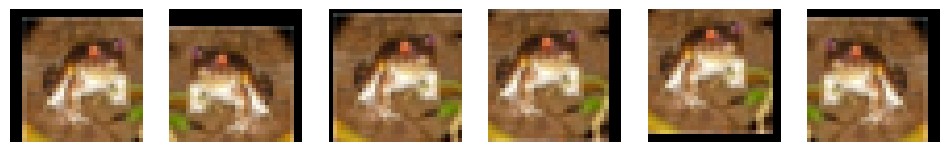

Kształt batcha: (128, 3, 32, 32) (batch × channels × height × width)


In [4]:
x, label = test_data[0]
print("Po normalizacji: min", round(x.min().item(), 2), "max", round(x.max().item(), 2))

mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax in axes:
    x, label = train_data[0]
    x = x * std + mean
    ax.imshow(x.permute(1, 2, 0).clamp(0, 1))
    ax.axis("off")
plt.show()

images, labels = next(iter(train_loader))
print("Kształt batcha:", tuple(images.shape), "(batch × channels × height × width)")

##### 2. Highway layer

In [5]:
class HighwayLayer(nn.Module):
    def __init__(self, channels, gate_bias=-2.0):
        super().__init__()
        self.H = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.T = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        nn.init.constant_(self.T.bias, gate_bias)

    def forward(self, x):
        h = F.relu(self.H(x))
        t = torch.sigmoid(self.T(x))
        return h * t + x * (1 - t)

In [6]:
layer = HighwayLayer(16)
x = torch.randn(8, 16, 32, 32)
y = layer(x)
print("input:", tuple(x.shape), "| output:", tuple(y.shape))

t = torch.sigmoid(layer.T(x))
print("mean T:", round(t.mean().item(), 3), "| sigmoid(-2):", round(torch.sigmoid(torch.tensor(-2.0)).item(), 3))

copy_layer = HighwayLayer(16, gate_bias=-20.0)
print("identity mapping (output == input)?", torch.allclose(copy_layer(x), x, atol=1e-5))

input: (8, 16, 32, 32) | output: (8, 16, 32, 32)
mean T: 0.132 | sigmoid(-2): 0.119
identity mapping (output == input)? True


##### 3. Model

In [ ]:
class Net(nn.Module):
    def __init__(self, depth, width):
        super().__init__()
        n = depth // 3  

        layers = []
        layers += [nn.Conv2d(3, width, kernel_size=3, padding=1), nn.ReLU()]
        layers += [HighwayLayer(width) for _ in range(n)]
        layers += [nn.Conv2d(width, 2 * width, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        layers += [HighwayLayer(2 * width) for _ in range(n)]
        layers += [nn.Conv2d(2 * width, 4 * width, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        layers += [HighwayLayer(4 * width) for _ in range(n)]
        layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(4 * width, 10)]
        self.layers = nn.Sequential(*layers)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")

    def forward(self, x):
        return self.layers(x)

In [8]:
model = Net(depth=20, width=32)
n_params = sum(p.numel() for p in model.parameters())
out = model(images[:4])
print("parameters:", n_params, "| output:", tuple(out.shape), "(4 obrazy × 10 klas)")

parameters: 2419658 | output: (4, 10) (4 obrazy × 10 klas)


##### 4. Training loop

In [9]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = F.cross_entropy(out, y)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)

    return total_loss / n, correct / n


def train_model(model, epochs, lr):
    model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    history = []

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        if math.isnan(train_loss):
            print(f"epoch {epoch:2d} | loss = nan: exploding gradients (za duży learning rate?). Przerywam.")
            break
        val_loss, val_acc = run_epoch(model, val_loader)
        scheduler.step()

        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        print(f"epoch {epoch:2d} | train: loss {train_loss:.3f}, accuracy {train_acc:.1%} | "
              f"val: loss {val_loss:.3f}, accuracy {val_acc:.1%}")

    return history

##### 5. Learning rate (LR range test)

In [10]:
def lr_range_test(model, start_lr=1e-5, end_lr=1.0, n_steps=200):
    model.to(device)
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=start_lr, momentum=0.9)
    factor = (end_lr / start_lr) ** (1 / n_steps)

    lrs, losses = [], []
    lr = start_lr
    data_iter = iter(train_loader)
    for step in range(n_steps):
        x, y = next(data_iter)
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lrs.append(lr)
        losses.append(loss.item())
        if not torch.isfinite(loss) or loss.item() > 4 * min(losses):
            break

        lr *= factor
        for group in optimizer.param_groups:
            group["lr"] = lr

    return lrs, losses


def smooth(values, beta=0.9):
    result, avg = [], values[0]
    for v in values:
        avg = beta * avg + (1 - beta) * v
        result.append(avg)
    return result


torch.manual_seed(42)
lrs, losses = lr_range_test(Net(depth=20, width=32))

smoothed = smooth(losses)
log_lrs = np.log10(lrs)

slopes = np.gradient(smoothed, log_lrs)
steepest = int(np.argmin(slopes))
lowest = min(range(len(smoothed)), key=lambda i: smoothed[i])



Najbardziej stromy spadek lossu przy LR ≈ 0.1259
najniższy loss przy LR ≈ 0.6683 → 10× mniej: 0.0668


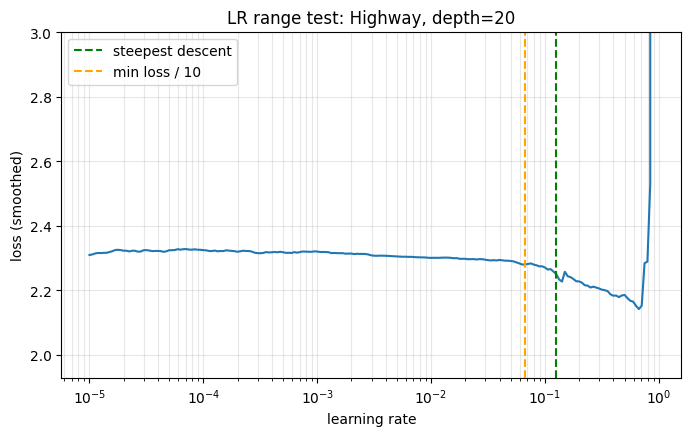

In [11]:
print(f"Najbardziej stromy spadek lossu przy LR ≈ {lrs[steepest]:.4f}")
print(f"najniższy loss przy LR ≈ {lrs[lowest]:.4f} → 10× mniej: {lrs[lowest] / 10:.4f}")

plt.figure(figsize=(8, 4.5))
plt.plot(lrs, smoothed)
plt.axvline(lrs[steepest], color="green", linestyle="--", label="steepest descent")
plt.axvline(lrs[lowest] / 10, color="orange", linestyle="--", label="min loss / 10")
plt.xscale("log")
plt.ylim(min(smoothed) * 0.9, smoothed[0] * 1.3)
plt.xlabel("learning rate")
plt.ylabel("loss (smoothed)")
plt.title("LR range test: Highway, depth=20")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

##### 6. Training

In [12]:
LR = 0.0668   
EPOCHS = 30
DEPTH = 20

torch.manual_seed(42)
model = Net(depth=DEPTH, width=32)
history = train_model(model, epochs=EPOCHS, lr=LR)

epoch  1 | train: loss 1.947, accuracy 25.4% | val: loss 1.649, accuracy 37.4%
epoch  2 | train: loss 1.527, accuracy 42.6% | val: loss 1.412, accuracy 48.9%
epoch  3 | train: loss 1.282, accuracy 53.3% | val: loss 1.212, accuracy 57.0%
epoch  4 | train: loss 1.095, accuracy 60.8% | val: loss 1.071, accuracy 63.5%
epoch  5 | train: loss 0.939, accuracy 67.2% | val: loss 0.944, accuracy 68.1%
epoch  6 | train: loss 0.825, accuracy 71.3% | val: loss 0.804, accuracy 72.1%
epoch  7 | train: loss 0.743, accuracy 74.4% | val: loss 0.774, accuracy 72.9%
epoch  8 | train: loss 0.670, accuracy 77.1% | val: loss 0.636, accuracy 77.9%
epoch  9 | train: loss 0.621, accuracy 78.5% | val: loss 0.635, accuracy 77.8%
epoch 10 | train: loss 0.584, accuracy 80.0% | val: loss 0.612, accuracy 79.0%
epoch 11 | train: loss 0.534, accuracy 81.6% | val: loss 0.550, accuracy 80.4%
epoch 12 | train: loss 0.504, accuracy 82.7% | val: loss 0.518, accuracy 82.5%
epoch 13 | train: loss 0.471, accuracy 83.6% | val: 

##### 7. Results

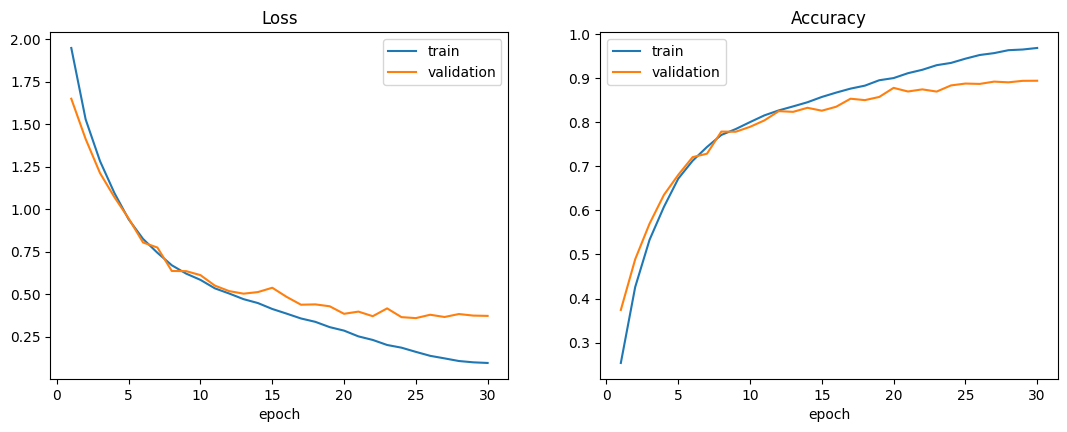

In [13]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs, [h["train_loss"] for h in history], label="train")
axes[0].plot(epochs, [h["val_loss"] for h in history], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs, [h["train_acc"] for h in history], label="train")
axes[1].plot(epochs, [h["val_acc"] for h in history], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.show()

In [14]:
test_loss, test_acc = run_epoch(model, test_loader)
print(f"Test set: loss {test_loss:.3f}, accuracy {test_acc:.1%}")

Test set: loss 0.405, accuracy 89.1%
